# Putative mitral and tufted cells

Results of `sniff-raster-python/mt_classifier.py`, which labels each OB unit as a putative mitral cell, tufted
cell or other from its baseline sniff-locking, following Ackels et al. 2020 (`reference/`).

The classifier input is the paper's: the spike histogram 0-700 ms after inhalation onset (10 ms bins), from sniffs
300-500 ms long, normalized to [0, 1]. Units whose histogram peak does not beat 95% of randomly aligned histograms are
`other` (`not_locked`). Without morphologically identified cells to train on, the labels that train the Fisher
discriminant come from the signature the paper describes: TCs lock with a clear mode in phase, MC phases are spread
broadly. A von Mises + uniform mixture on the preferred phases of locked units gives these, and the discriminant then
labels every locked unit; units with posterior < 0.8 for either type are `other` (`ambiguous`).

The training labels come from the phase of the same histograms, so the leave-one-out accuracy says how well the
discriminant reproduces them, not how well it recovers true cell types.

In [1]:
import sys
sys.path.insert(0, 'sniff-raster-python')  # the analysis modules live there
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import mt_classifier as mt

inv = pd.read_csv(mt.OUT_FILE, dtype={'mouse': str})
h = np.load(mt.OUT_FILE.replace('mt_cell_inventory.csv', 'mt_histograms.npz'))
assert (h['cluster'] == inv['cluster']).all() and (h['session'] == inv['session']).all()
lat = h['latency_ms']
norm = mt.normalize(h['hist'])
colors = {'tufted': 'tab:blue', 'mitral': 'tab:red', 'other': 'tab:gray'}
print(inv['cell_type'].value_counts().to_string())
print(inv['other_reason'].value_counts().to_string())

cell_type
tufted    897
other     722
mitral    349
other_reason
not_locked    650
ambiguous      69
few_spikes      3


## Counts per mouse

In [2]:
pd.crosstab(inv['mouse'], inv['cell_type'], margins=True)

cell_type,mitral,other,tufted,All
mouse,,,,
9000,72,87,80,239
9002,54,135,40,229
9003,2,40,128,170
9005,45,48,187,280
9006,129,235,95,459
9007,4,69,61,134
9008,37,92,137,266
9009,6,16,169,191
All,349,722,897,1968


## Phase mixture

Preferred phase (warped sniff cycle, 0 = inhalation onset) of locked units, with the fitted von Mises (TC) and uniform
(MC) components. Units with mixture posterior > 0.9 for either component trained the discriminant.

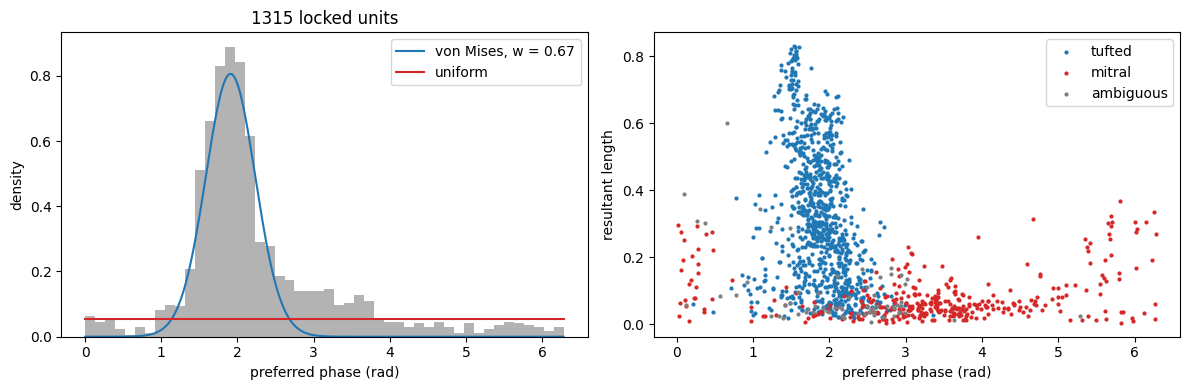

In [3]:
locked = inv[inv['locked']]
post, mix = mt.fit_phase_mixture(locked['pref_phase_rad'].to_numpy())
x = np.linspace(0, 2 * np.pi, 400)
vm = np.exp(mix['kappa'] * (np.cos(x - mix['mu']) - 1)) / (2 * np.pi * mt.i0e(mix['kappa']))
bins = np.linspace(0, 2 * np.pi, 49)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(locked['pref_phase_rad'], bins, density=True, color='0.7')
ax[0].plot(x, mix['w'] * vm, c=colors['tufted'], label=f"von Mises, w = {mix['w']:.2f}")
ax[0].plot(x, np.full_like(x, (1 - mix['w']) / (2 * np.pi)), c=colors['mitral'], label='uniform')
ax[0].set(xlabel='preferred phase (rad)', ylabel='density', title=f'{len(locked)} locked units')
ax[0].legend()
for t in ('tufted', 'mitral'):
    s = locked['cell_type'] == t
    ax[1].scatter(locked.loc[s, 'pref_phase_rad'], locked.loc[s, 'resultant_length'], s=4, c=colors[t], label=t)
s = locked['cell_type'] == 'other'
ax[1].scatter(locked.loc[s, 'pref_phase_rad'], locked.loc[s, 'resultant_length'], s=4, c=colors['other'], label='ambiguous')
ax[1].set(xlabel='preferred phase (rad)', ylabel='resultant length')
ax[1].legend()
plt.tight_layout()

## Histograms by class

Each row is a unit's normalized histogram, sorted by preferred phase. Right: mean normalized histogram and mean rate per
class.

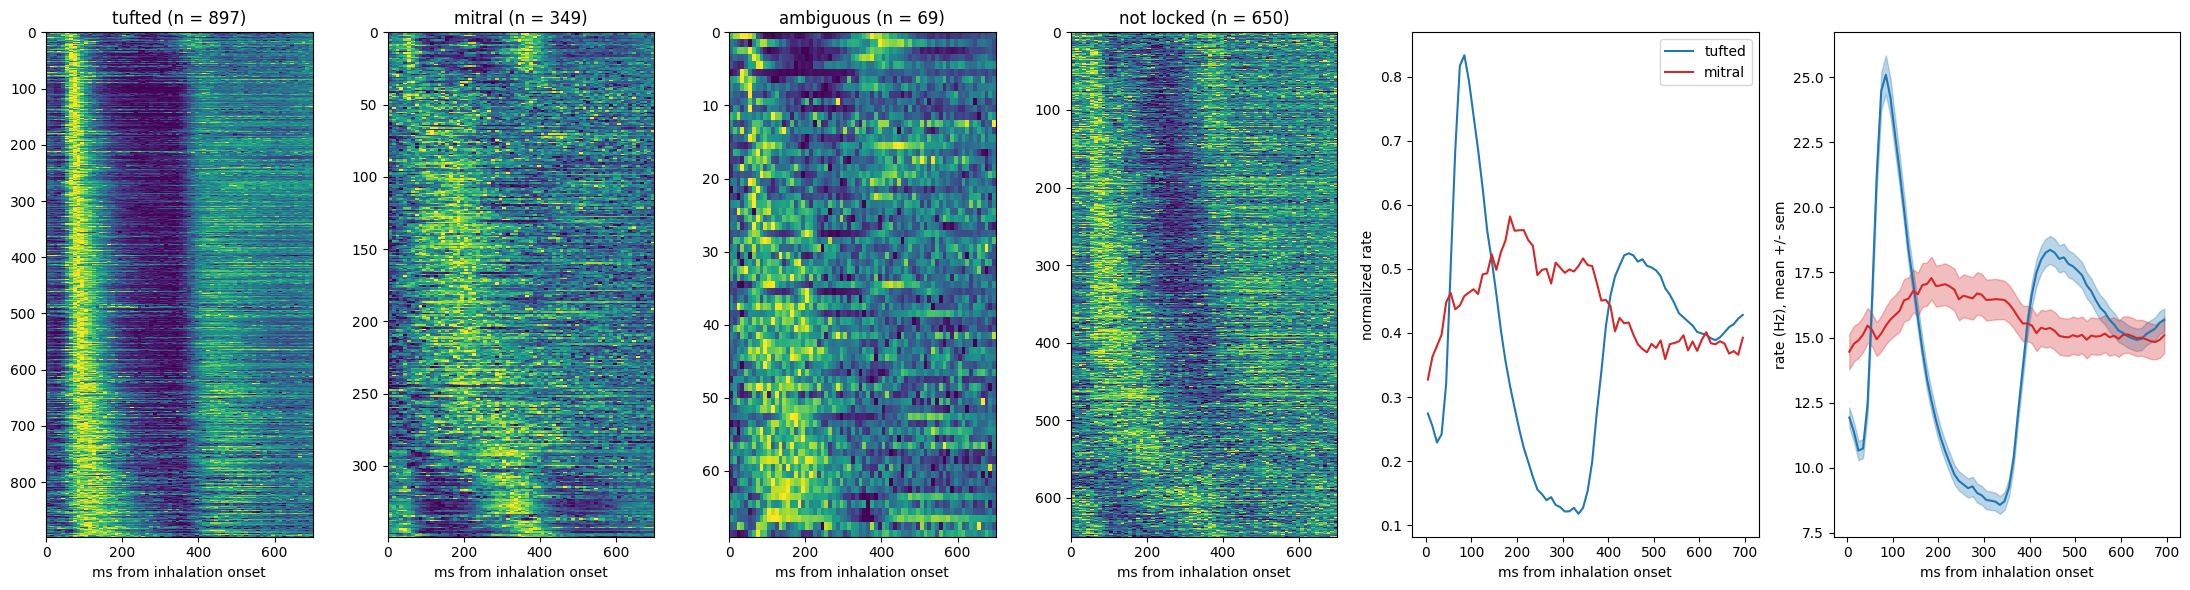

In [4]:
groups = [('tufted', inv['cell_type'] == 'tufted'), ('mitral', inv['cell_type'] == 'mitral'),
          ('ambiguous', inv['other_reason'] == 'ambiguous'), ('not locked', inv['other_reason'] == 'not_locked')]
fig, ax = plt.subplots(1, 6, figsize=(22, 6), gridspec_kw=dict(width_ratios=[1, 1, 1, 1, 1.3, 1.3]))
for a, (name, s) in zip(ax, groups):
    s = s.to_numpy()
    o = np.argsort(inv.loc[s, 'pref_phase_rad'].to_numpy())
    a.imshow(norm[s][o], aspect='auto', extent=[0, 700, s.sum(), 0], interpolation='none')
    a.set(title=f'{name} (n = {s.sum()})', xlabel='ms from inhalation onset')
for name, s in groups[:2]:
    s = s.to_numpy()
    ax[4].plot(lat, np.nanmean(norm[s], 0), c=colors[name], label=name)
    m, sd = h['hist'][s].mean(0), h['hist'][s].std(0) / np.sqrt(s.sum())
    ax[5].plot(lat, m, c=colors[name], label=name)
    ax[5].fill_between(lat, m - sd, m + sd, color=colors[name], alpha=0.3)
ax[4].set(xlabel='ms from inhalation onset', ylabel='normalized rate')
ax[5].set(xlabel='ms from inhalation onset', ylabel='rate (Hz), mean +/- sem')
ax[4].legend()
plt.tight_layout()

## Validation

- leave-one-out accuracy on the training units, and the same with histograms aligned to random onsets (the paper's
  control; should fall to chance)
- split-half consistency: the discriminant applied to histograms from odd and from even sniffs separately

In [5]:
pd.read_csv(mt.OUT_FILE.replace('mt_cell_inventory', 'mt_classifier_summary'), index_col=0)

,value
statistic,
n_units,1968.000000
n_locked,1315.000000
mixture_w_tufted,0.665682
mixture_mu_rad,1.908873
mixture_kappa,9.471705
n_train_tufted,666.000000
n_train_mitral,280.000000
loo_accuracy,0.968288
loo_accuracy_random_alignment,0.654334


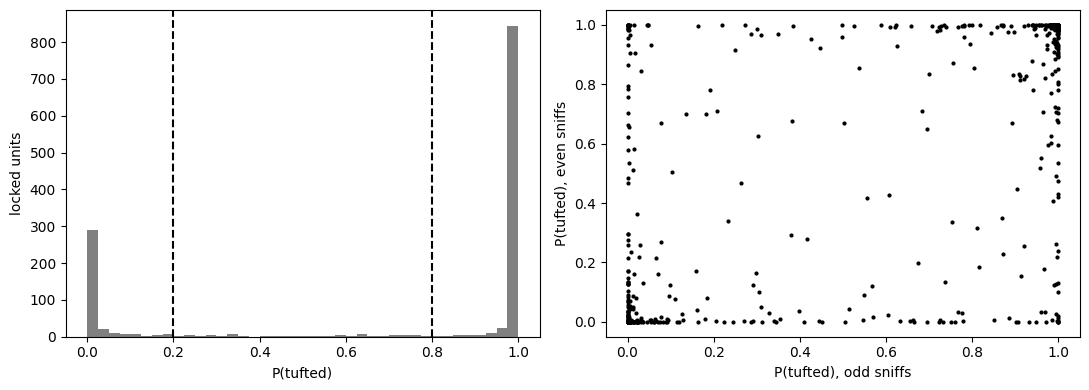

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(inv['p_tufted'].dropna(), np.linspace(0, 1, 41), color='0.5')
for v in (1 - mt.CALL_POSTERIOR, mt.CALL_POSTERIOR):
    ax[0].axvline(v, c='k', ls='--')
ax[0].set(xlabel='P(tufted)', ylabel='locked units')
ax[1].scatter(inv['p_tufted_odd'], inv['p_tufted_even'], s=4, c='k')
ax[1].set(xlabel='P(tufted), odd sniffs', ylabel='P(tufted), even sniffs')
plt.tight_layout()